In [23]:
# TASK 1

from textblob import TextBlob

def sentimentAnalyzer(text):
    blob = TextBlob(text)
    if blob.sentiment.polarity > 0.2:
        return 'Positive'
    elif 0.2 >= blob.sentiment.polarity >= -0.2:
        return 'Neutral'
    else:
        return 'Negative'

In [24]:
# TASK 2

from prettytable import PrettyTable

sentiment_words = ['happy', 'exciting', 'good', 'rich', 'smile', 'sad', 'disappointed', 'bad', 'poor', 'anger', 'food', 'animal']
table = PrettyTable(['Word', 'Polarity', 'Sentiment'])
for word in sentiment_words:
    table.add_row([word, TextBlob(word).sentiment.polarity, sentimentAnalyzer(word)])
print(table)

+--------------+---------------------+-----------+
|     Word     |       Polarity      | Sentiment |
+--------------+---------------------+-----------+
|    happy     |         0.8         |  Positive |
|   exciting   |         0.3         |  Positive |
|     good     |         0.7         |  Positive |
|     rich     |        0.375        |  Positive |
|    smile     |         0.3         |  Positive |
|     sad      |         -0.5        |  Negative |
| disappointed |        -0.75        |  Negative |
|     bad      | -0.6999999999999998 |  Negative |
|     poor     |         -0.4        |  Negative |
|    anger     |         -0.7        |  Negative |
|     food     |         0.0         |  Neutral  |
|    animal    |         0.0         |  Neutral  |
+--------------+---------------------+-----------+


In [25]:
#TASK 3

import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('ggplot')

df = pd.read_csv('../../Desktop/apple_iphone_11_reviews.csv')
df.head(1000)

,index,product,helpful_count,total_comments,url,review_country,reviewed_at,review_text,review_rating,product_company,profile_name,review_title
0,0,Apple iPhone XR (64GB) - Black,"5,087 people found this helpful",24,https://www.amazon.in/Apple-iPhone-XR-64GB-Bla...,India,2018-12-12,NOTE:,3.0 out of 5 stars,Apple,Sameer Patil,"Which iPhone you should Purchase ? iPhone 8, X..."
1,1,Apple iPhone XR (64GB) - Black,"2,822 people found this helpful",6,https://www.amazon.in/Apple-iPhone-XR-64GB-Bla...,India,2018-11-17,Very bad experience with this iPhone xr phone....,1.0 out of 5 stars,Apple,Amazon Customer,Don't buy iPhone xr from Amazon.
2,2,Apple iPhone XR (64GB) - Black,"1,798 people found this helpful",0,https://www.amazon.in/Apple-iPhone-XR-64GB-Bla...,India,2019-01-27,Amazing phone with amazing camera coming from ...,5.0 out of 5 stars,Apple,A,Happy with the purchase
3,3,Apple iPhone XR (64GB) - Black,"1,366 people found this helpful",14,https://www.amazon.in/Apple-iPhone-XR-64GB-Bla...,India,2019-05-02,So I got the iPhone XR just today. The product...,1.0 out of 5 stars,Apple,Shubham Dutta,Amazon is not an apple authorised reseller. Pl...
4,4,Apple iPhone XR (64GB) - Black,536 people found this helpful,5,https://www.amazon.in/Apple-iPhone-XR-64GB-Bla...,India,2019-05-24,I've been an android user all my life until I ...,5.0 out of 5 stars,Apple,Nepuni Lokho,Excellent Battery life and buttery smooth UI
...,...,...,...,...,...,...,...,...,...,...,...,...
995,995,Apple iPhone XR (64GB) - Black,0,0,https://www.amazon.in/Apple-iPhone-XR-64GB-Bla...,India,2020-03-06,Best user experience till date.,5.0 out of 5 stars,Apple,Amazon Customer,Ultimate user experience
996,996,Apple iPhone XR (64GB) - Black,0,0,https://www.amazon.in/Apple-iPhone-XR-64GB-Bla...,India,2019-10-14,Received genuine product with one year free sc...,5.0 out of 5 stars,Apple,Hardik Walse,Fabulous ❤
997,997,Apple iPhone XR (64GB) - Black,0,0,https://www.amazon.in/Apple-iPhone-XR-64GB-Bla...,India,2019-10-17,it’s been a week since i got this and it’s bee...,5.0 out of 5 stars,Apple,Surya kanth,fantastic
998,998,Apple iPhone XR (64GB) - Black,0,0,https://www.amazon.in/Apple-iPhone-XR-64GB-Bla...,India,2019-07-27,I must say best iPhone device of apple. Colour...,5.0 out of 5 stars,Apple,Satyajit Auddya,Best iPhone from Apple


In [26]:
product_names = df['product'].unique()
row_count = df.shape[0]
col_count = df.shape[1]
shortest_review = df['review_text'].str.len().min()
longest_review = df['review_text'].str.len().max()
average_review = df['review_text'].str.len().mean()

print("product name: " + product_names[0])
print("number of reviews: " + str(row_count))
print("number of columns: " + str(col_count))
print("shortest review length: " + str(shortest_review))
print("longest review length: " + str(longest_review))
print("average review length: " + str(average_review))

product name: Apple iPhone XR (64GB) - Black
number of reviews: 5010
number of columns: 12
shortest review length: 1.0
longest review length: 1001.0
average review length: 65.6145396444977


In [27]:
# TASK 4

df['review_text'] = df['review_text'].astype(str)
df['sentiment'] = df['review_text'].apply(sentimentAnalyzer)
df[['review_rating', 'review_text', 'sentiment']].head(1000)

,review_rating,review_text,sentiment
0,3.0 out of 5 stars,NOTE:,Neutral
1,1.0 out of 5 stars,Very bad experience with this iPhone xr phone....,Neutral
2,5.0 out of 5 stars,Amazing phone with amazing camera coming from ...,Positive
3,1.0 out of 5 stars,So I got the iPhone XR just today. The product...,Neutral
4,5.0 out of 5 stars,I've been an android user all my life until I ...,Positive
...,...,...,...
995,5.0 out of 5 stars,Best user experience till date.,Positive
996,5.0 out of 5 stars,Received genuine product with one year free sc...,Positive
997,5.0 out of 5 stars,it’s been a week since i got this and it’s bee...,Positive
998,5.0 out of 5 stars,I must say best iPhone device of apple. Colour...,Positive


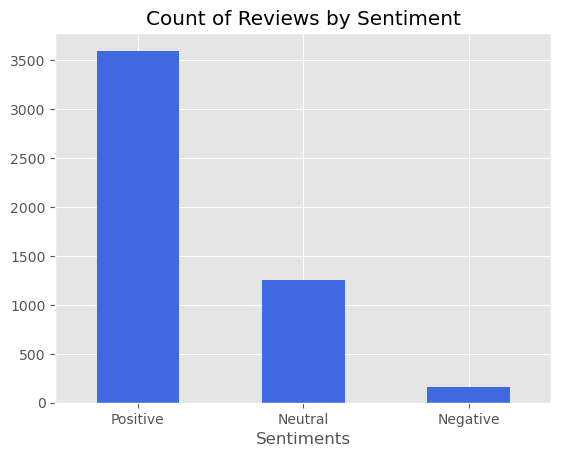

In [28]:
# TASK 5

# visualization of count of reviews by sentiment

graph = df['sentiment'].value_counts().plot(kind = 'bar', title = 'Count of Reviews by Sentiment', color = 'royalblue', rot = 0)
graph.set_xlabel('Sentiments')
plt.show()

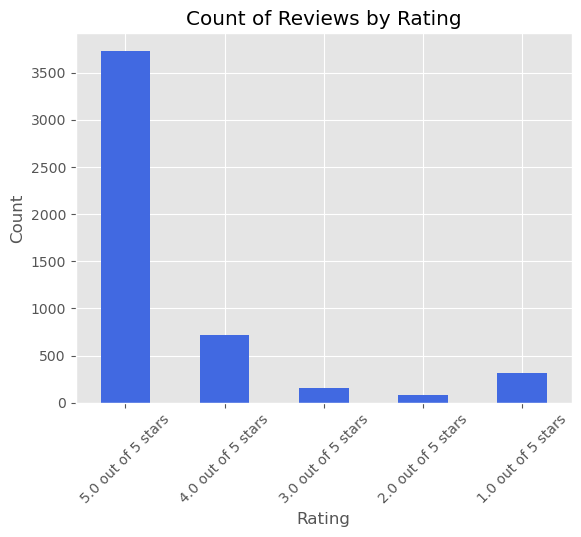

In [29]:
# visualization of count of reviews by rating

rating_order = ['5.0 out of 5 stars', '4.0 out of 5 stars', '3.0 out of 5 stars', '2.0 out of 5 stars', '1.0 out of 5 stars']

df['review_rating'] = pd.Categorical(df['review_rating'], categories = rating_order, ordered = True)
rating_counts = df['review_rating'].value_counts().reindex(rating_order)

graph = rating_counts.plot(kind='bar', title='Count of Reviews by Rating', color='royalblue')
graph.set_xlabel('Rating')
plt.ylabel('Count')
plt.xticks(rotation = 45)
plt.show()

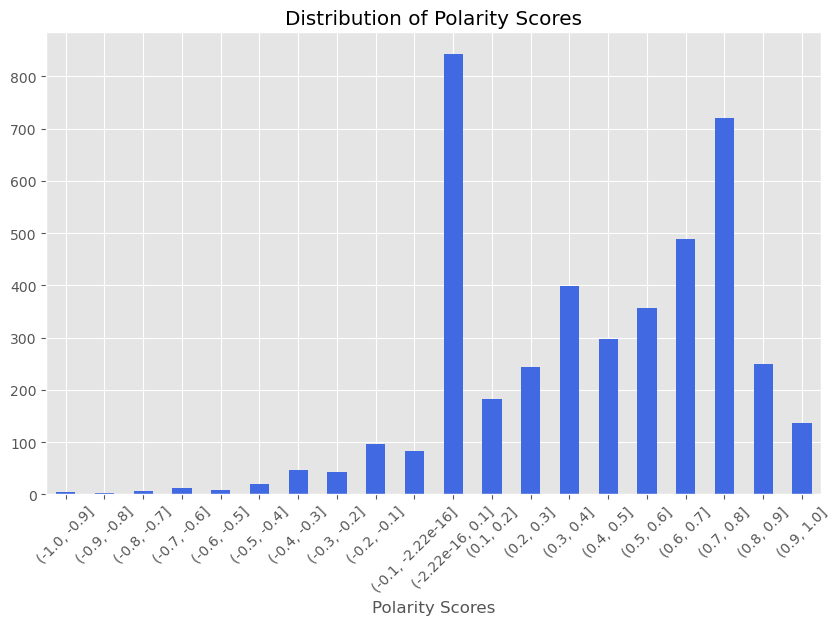

In [30]:
# visualization of the distribution of polarity scores

import numpy as np

def get_polarity(text):
    return TextBlob(text).sentiment.polarity

df['polarity'] = df['review_text'].apply(get_polarity)
polarity_increment = np.arange(-1.0, 1.1, 0.1)
df['polarity_increment'] = pd.cut(df['polarity'], bins = polarity_increment)
polarity_increment_counts = df['polarity_increment'].value_counts().sort_index()

plt.figure(figsize = (10, 6))
polarity_increment_counts.plot(kind = 'bar', color = 'royalblue')
plt.title('Distribution of Polarity Scores')
plt.xlabel('Polarity Scores')

plt.xticks(rotation = 45)
plt.show()

In [31]:
df['polarity'] = df['review_text'].apply(get_polarity)
df[['review_rating', 'review_text', 'sentiment', 'polarity']].head(1000)

,review_rating,review_text,sentiment,polarity
0,3.0 out of 5 stars,NOTE:,Neutral,0.000000
1,1.0 out of 5 stars,Very bad experience with this iPhone xr phone....,Neutral,-0.152000
2,5.0 out of 5 stars,Amazing phone with amazing camera coming from ...,Positive,0.666667
3,1.0 out of 5 stars,So I got the iPhone XR just today. The product...,Neutral,-0.033902
4,5.0 out of 5 stars,I've been an android user all my life until I ...,Positive,0.493750
...,...,...,...,...
995,5.0 out of 5 stars,Best user experience till date.,Positive,1.000000
996,5.0 out of 5 stars,Received genuine product with one year free sc...,Positive,0.500000
997,5.0 out of 5 stars,it’s been a week since i got this and it’s bee...,Positive,0.600000
998,5.0 out of 5 stars,I must say best iPhone device of apple. Colour...,Positive,0.433333


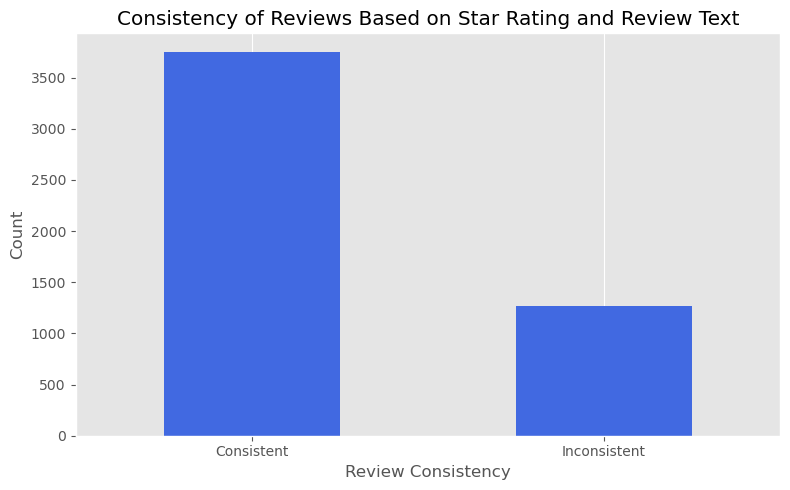

In [32]:
def review_consistency(review_text, review_rating):

    review_rating = int(review_rating[0])
    review_sentiment = TextBlob(review_text).sentiment.polarity

    if review_rating == 5 or review_rating == 4:
        expected_sentiment = 0.2
    elif review_rating == 3:
        expected_sentiment = 0.0
    elif review_rating == 2 or review_rating == 1:
        expected_sentiment = -0.2
    else:
        return "Invalid star rating."

    if (review_sentiment >= expected_sentiment and review_rating >= 3) or (review_sentiment < expected_sentiment and review_rating < 3):
        return "Consistent"
    else:
        return "Inconsistent"

df['consistency'] = df.apply(lambda row: review_consistency(row['review_text'], row['review_rating']), axis=1)
consistency_counts = df['consistency'].value_counts()

plt.figure(figsize=(8, 5))
consistency_counts.plot(kind = 'bar', color = 'royalblue', rot = 0)
plt.title('Consistency of Reviews Based on Star Rating and Review Text')
plt.xlabel('Review Consistency')
plt.ylabel('Count')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

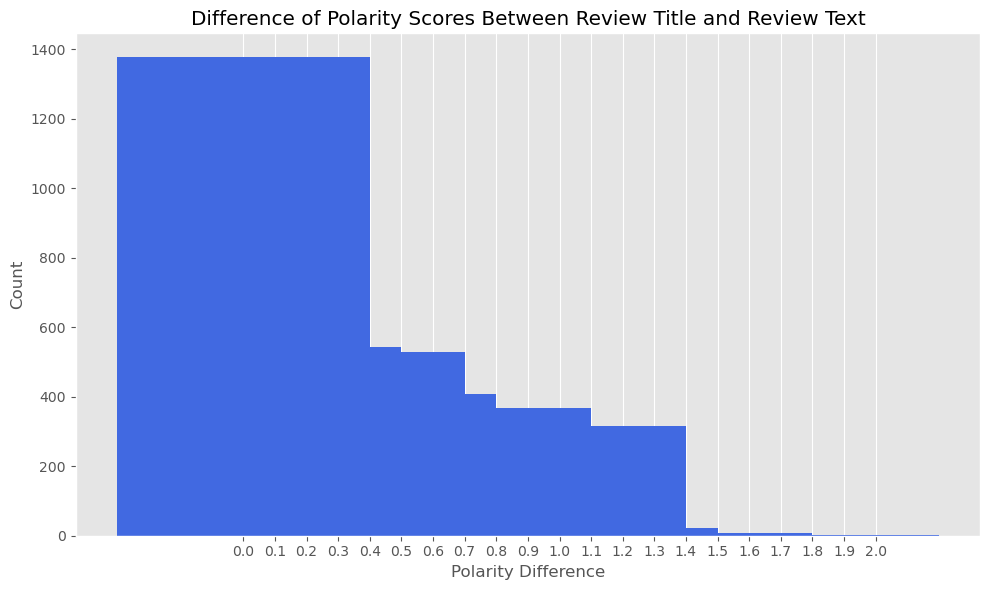

,review_title,review_text,polarity_difference
0,"Which iPhone you should Purchase ? iPhone 8, X...",NOTE:,0.0
1,Don't buy iPhone xr from Amazon.,Very bad experience with this iPhone xr phone....,0.2
2,Happy with the purchase,Amazing phone with amazing camera coming from ...,0.1
3,Amazon is not an apple authorised reseller. Pl...,So I got the iPhone XR just today. The product...,0.0
4,Excellent Battery life and buttery smooth UI,I've been an android user all my life until I ...,0.2
...,...,...,...
995,Ultimate user experience,Best user experience till date.,1.0
996,Fabulous ❤,Received genuine product with one year free sc...,0.1
997,fantastic,it’s been a week since i got this and it’s bee...,0.2
998,Best iPhone from Apple,I must say best iPhone device of apple. Colour...,0.6


In [33]:
df['review_title'] = df['review_title'].astype(str)
df['title polarity'] = (df['review_title'].apply(get_polarity))


def text_title_difference(review_title, review_text):
    text_polarity = TextBlob(review_text).sentiment.polarity
    title_polarity = TextBlob(review_title).sentiment.polarity

    difference = abs(text_polarity - title_polarity)

    return round(difference, 1)

df['polarity_difference'] = df.apply(lambda row: text_title_difference(row['review_title'], row['review_text']), axis=1)

polarity_diff_counts = df['polarity_difference'].value_counts().sort_index()

plt.figure(figsize=(10, 6))
bars = plt.bar(polarity_diff_counts.index.astype(float), polarity_diff_counts.values, color = 'royalblue')
plt.title('Difference of Polarity Scores Between Review Title and Review Text')
plt.xlabel('Polarity Difference')
plt.ylabel('Count')

plt.xticks(ticks = np.arange(0, 2.1, 0.1), labels = [f"{x:.1f}" for x in np.arange(0, 2.1, 0.1)])

plt.grid(axis='y')
plt.tight_layout()
plt.show()

df[['review_title', 'review_text', 'polarity_difference']].head(1000)

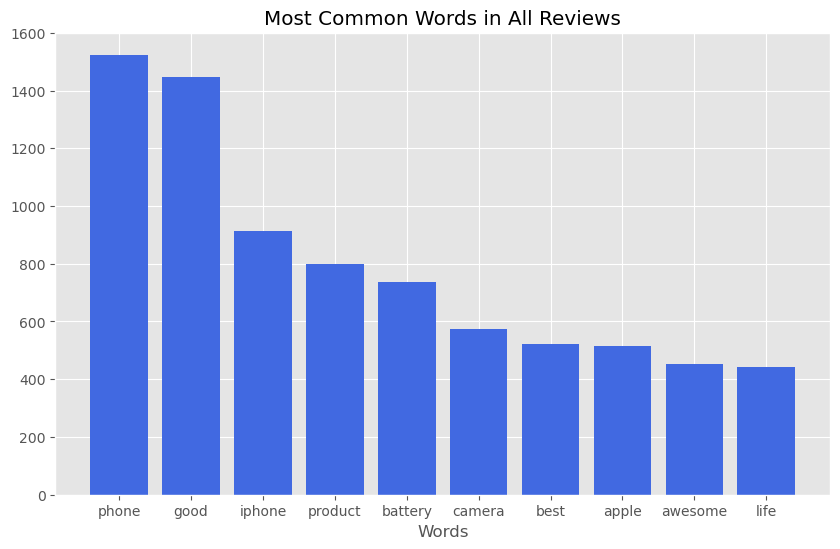

In [34]:
# EXTRA: visualization of word frequency

import matplotlib.pyplot as plt
from collections import Counter
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import string

stop_words = set(stopwords.words('english') + list(string.punctuation))

words = []
for review in df['review_text']:
    tokens = word_tokenize(review.lower())
    words.extend([word for word in tokens if word.isalpha() and word not in stop_words])

word_counts = Counter(words)
most_common_words = word_counts.most_common(10)
words, counts = zip(*most_common_words)

plt.figure(figsize = (10, 6))
plt.bar(words, counts, color = 'royalblue')
plt.title('Most Common Words in All Reviews')
plt.xlabel('Words')
plt.show()


In [35]:
# TASK 6

df.to_csv('iphone_sentiment_analysis.csv', index=False)